# 04 – Data Integration & Quality Assessment

**NASA Challenge – Inspiration4**

Notebook đọc trực tiếp các thư mục OSD đã giải nén; tích hợp CBC + Serum, tổng hợp Plasma Proteomics, kiểm tra chất lượng và xuất CSV.

> Không cần file ZIP hoặc thư mục `data_raw`. Giữ nguyên dữ liệu nguồn trong các thư mục OSD.


In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Locate project root (the folder containing OSD-569, OSD-571 and OSD-575)
def find_project_root():
    current = Path.cwd().resolve()
    for folder in [current, *current.parents]:
        required = ["OSD-569", "OSD-571", "OSD-575"]
        if all((folder / name).is_dir() for name in required):
            return folder
    raise FileNotFoundError(
        "Cannot find project root containing OSD-569, OSD-571 and OSD-575. "
        "Open Jupyter/VS Code at the nasa challenge project folder."
    )

BASE_DIR = find_project_root()
RAW_DIR = BASE_DIR
OUT_DIR = BASE_DIR / "processed_data"
FIG_DIR = BASE_DIR / "figures"

OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", BASE_DIR)
print("Input mode: extracted OSD folders (no ZIP extraction required)")
print("Processed output:", OUT_DIR)
print("Figures:", FIG_DIR)


Project root: /home/claude/proj/P
Input mode: extracted OSD folders (no ZIP extraction required)
Processed output: /home/claude/proj/P/processed_data
Figures: /home/claude/proj/P/figures


In [2]:
# 1. Load transformed datasets and metadata
cbc_path = RAW_DIR / "OSD-569" / "LSDS-7_Complete_Blood_Count_CBC_TRANSFORMED.csv"
serum_path = RAW_DIR / "OSD-575" / "OSD575_CMP_Immunoassay_Combined.csv"
plasma_path = RAW_DIR / "OSD-571" / "GLDS-563_proteomics_plasma_proteomics_preprocessed_data.tsv"
plasma_meta_path = RAW_DIR / "OSD-571" / "GLDS-563_proteomics_plasma_metadata_all_samples_collapsed.csv"

cbc = pd.read_csv(cbc_path)
serum = pd.read_csv(serum_path)
plasma_long = pd.read_csv(plasma_path, sep="\t")
plasma_metadata = pd.read_csv(plasma_meta_path)

for name, df in {"CBC": cbc, "Serum": serum, "Plasma long": plasma_long,
                 "Plasma metadata": plasma_metadata}.items():
    print(f"{name}: {df.shape}; missing={df.isna().sum().sum()}; duplicates={df.duplicated().sum()}")


CBC: (28, 61); missing=21; duplicates=0
Serum: (28, 200); missing=81; duplicates=0
Plasma long: (81817, 9); missing=80636; duplicates=0
Plasma metadata: (21, 5); missing=0; duplicates=0


In [3]:
# 2. Normalize Sample ID and integrate CBC + Serum
def normalize_sample(name, sample_type):
    pattern = rf"(C\d+)_{sample_type}_([LR][+-]\d+)"
    match = re.search(pattern, str(name), flags=re.IGNORECASE)
    return f"{match.group(1)}_{match.group(2)}" if match else None

cbc["Sample_ID"] = cbc["Sample Name"].apply(lambda x: normalize_sample(x, "whole-blood"))
serum["Sample_ID"] = serum["Sample Name"].apply(lambda x: normalize_sample(x, "serum"))

assert cbc["Sample_ID"].notna().all(), "Có Sample ID CBC không chuẩn hóa được"
assert serum["Sample_ID"].notna().all(), "Có Sample ID Serum không chuẩn hóa được"
assert cbc["Sample_ID"].is_unique and serum["Sample_ID"].is_unique

cbc_serum = cbc.merge(
    serum, on="Sample_ID", how="inner",
    suffixes=("_CBC", "_Serum"), validate="one_to_one"
)
cbc_serum["Astronaut"] = cbc_serum["Sample_ID"].str.extract(r"^(C\d+)")
cbc_serum["Timepoint"] = cbc_serum["Sample_ID"].str.extract(r"_(L[+-]\d+|R[+-]\d+)$")
cbc_serum["Phase"] = np.where(cbc_serum["Timepoint"].str.startswith("L-"),
                              "Preflight", "Postflight")
print("CBC + Serum:", cbc_serum.shape)
print(cbc_serum["Phase"].value_counts())


CBC + Serum: (28, 265)
Phase
Postflight    16
Preflight     12
Name: count, dtype: int64


In [4]:
# 3. Aggregate Plasma Proteomics technical plate measurements
# Remove terminal plate suffix (-1/-2/...) to match biological sample metadata.
plasma_long["Sample_Base"] = plasma_long["Sample Name"].astype(str).str.replace(
    r"-\d+$", "", regex=True
)
plasma_agg = (
    plasma_long.groupby(["Sample_Base", "Protein Group"], as_index=False)["Intensity (Log10)"]
    .mean()
)
plasma_wide = plasma_agg.pivot(
    index="Sample_Base", columns="Protein Group", values="Intensity (Log10)"
).reset_index()

plasma_metadata = plasma_metadata.rename(columns={"Sample_name": "Sample_Base"})
assert plasma_metadata["Sample_Base"].is_unique
plasma = plasma_wide.merge(
    plasma_metadata, on="Sample_Base", how="left", validate="one_to_one"
)
assert plasma["Astronaut"].notna().all(), "Có mẫu proteomics chưa khớp metadata"
plasma["Phase"] = plasma["PreVpost"]
plasma = plasma.rename(columns={"Sample_Base": "Sample_ID"})
print("Plasma integrated:", plasma.shape)
print(plasma["Phase"].value_counts())


Plasma integrated: (21, 2998)
Phase
Preflight     11
Postflight    10
Name: count, dtype: int64


In [5]:
# 4. Feature filtering for exploratory / downstream analysis
# No imputation is performed here. Imputation must be fitted on training folds only.
def filter_features(df, id_cols, drop_range=False, missing_threshold=0.50):
    numeric = df.select_dtypes(include=np.number).copy()
    constant_cols = numeric.columns[numeric.nunique(dropna=True) <= 1].tolist()
    numeric = numeric.drop(columns=constant_cols)

    range_cols = []
    if drop_range:
        range_cols = [
            c for c in numeric.columns
            if "_range_min_" in c or "_range_max_" in c
            or c.endswith("_range_min") or c.endswith("_range_max")
        ]
        numeric = numeric.drop(columns=range_cols)

    missing_rate = numeric.isna().mean()
    high_missing_cols = missing_rate[missing_rate > missing_threshold].index.tolist()
    numeric = numeric.drop(columns=high_missing_cols)

    result = pd.concat(
        [df[id_cols].reset_index(drop=True), numeric.reset_index(drop=True)], axis=1
    )
    report = {
        "numeric_features_before": df.select_dtypes(include=np.number).shape[1],
        "constant_features_removed": len(constant_cols),
        "range_columns_removed": len(range_cols),
        "high_missing_features_removed": len(high_missing_cols),
        "features_retained": numeric.shape[1],
        "missing_cells_retained": int(numeric.isna().sum().sum())
    }
    return result, report

cbc_ids = ["Sample_ID", "Astronaut", "Timepoint", "Phase"]
plasma_ids = ["Sample_ID", "Astronaut", "PreVpost", "Timepoint",
              "ImmediateVLongTerm", "Phase"]

cbc_ml, cbc_filter_report = filter_features(cbc_serum, cbc_ids, drop_range=True)
plasma_ml, plasma_filter_report = filter_features(plasma, plasma_ids)

filter_report = pd.DataFrame([
    {"Dataset": "CBC + Serum", "Samples": len(cbc_serum), **cbc_filter_report},
    {"Dataset": "Plasma Proteomics", "Samples": len(plasma), **plasma_filter_report}
])
filter_report


             Dataset  Samples  numeric_features_before  constant_features_removed  range_columns_removed  high_missing_features_removed  features_retained  missing_cells_retained
0        CBC + Serum       28                      259                         64                     12                              1                182                       8
1  Plasma Proteomics       21                     2992                         51                      0                            858               2083                    3641

In [6]:
# 5. Data quality report
quality_frames = [
    ("OSD-569 CBC", cbc),
    ("OSD-575 CMP + Immune EvePanel", serum),
    ("CBC + Serum Integrated", cbc_serum),
    ("OSD-571 Plasma Proteomics long", plasma_long),
    ("Plasma Proteomics aggregated", plasma),
]
quality_report = pd.DataFrame([
    {
        "Dataset": name, "Rows": len(df), "Columns": df.shape[1],
        "Missing_Cells": int(df.isna().sum().sum()),
        "Missing_Rate": float(df.isna().sum().sum() / (df.shape[0] * df.shape[1])),
        "Duplicate_Rows": int(df.duplicated().sum())
    }
    for name, df in quality_frames
])
quality_report


                          Dataset   Rows  Columns  Missing_Cells  Missing_Rate  Duplicate_Rows
0                     OSD-569 CBC     28       62             21      0.012097               0
1   OSD-575 CMP + Immune EvePanel     28      201             81      0.014392               0
2          CBC + Serum Integrated     28      265            102      0.013747               0
3  OSD-571 Plasma Proteomics long  81817       10          80636      0.098557               0
4    Plasma Proteomics aggregated     21     2998          18113      0.287700               0

        Phase  Samples            Dataset
0  Postflight       16        CBC + Serum
1   Preflight       12        CBC + Serum
2  Postflight       10  Plasma Proteomics
3   Preflight       11  Plasma Proteomics

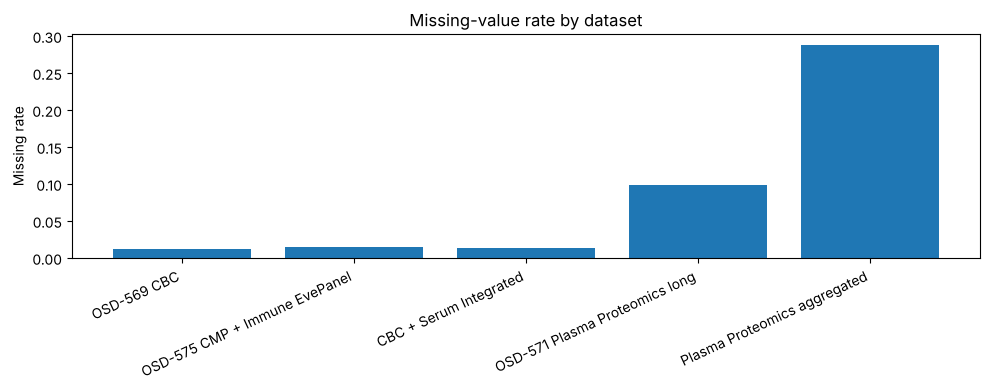

In [7]:
# 6. Visualize missingness and phase counts
missing_summary = quality_report[["Dataset", "Missing_Rate"]].copy()
plt.figure(figsize=(10, 4))
plt.bar(missing_summary["Dataset"], missing_summary["Missing_Rate"])
plt.xticks(rotation=25, ha="right")
plt.ylabel("Missing rate")
plt.title("Missing-value rate by dataset")
plt.tight_layout()
plt.savefig(FIG_DIR / "missing_rate_by_dataset.png", dpi=150)
plt.show()

phase_summary = pd.concat([
    cbc_serum.groupby("Phase").size().rename("Samples").reset_index().assign(Dataset="CBC + Serum"),
    plasma.groupby("Phase").size().rename("Samples").reset_index().assign(Dataset="Plasma Proteomics")
], ignore_index=True)
phase_summary


In [8]:
# 7. Export processed tables and reports
outputs = {
    "CBC_Serum_Integrated.csv": cbc_serum,
    "Plasma_Proteomics_Integrated.csv": plasma,
    "CBC_Serum_Features_Filtered.csv": cbc_ml,
    "Plasma_Proteomics_Features_Filtered.csv": plasma_ml,
    "Data_Quality_Report.csv": quality_report,
    "Feature_Filtering_Report.csv": filter_report,
    "Sample_Phase_Summary.csv": phase_summary,
}
for filename, frame in outputs.items():
    frame.to_csv(OUT_DIR / filename, index=False)

print("Exported:")
for filename in outputs:
    print("-", OUT_DIR / filename)


Exported:
- /home/claude/proj/P/processed_data/CBC_Serum_Integrated.csv
- /home/claude/proj/P/processed_data/Plasma_Proteomics_Integrated.csv
- /home/claude/proj/P/processed_data/CBC_Serum_Features_Filtered.csv
- /home/claude/proj/P/processed_data/Plasma_Proteomics_Features_Filtered.csv
- /home/claude/proj/P/processed_data/Data_Quality_Report.csv
- /home/claude/proj/P/processed_data/Feature_Filtering_Report.csv
- /home/claude/proj/P/processed_data/Sample_Phase_Summary.csv


## 8. Interpretation and limitations

- CBC + Serum được ghép theo `Sample_ID`; 28 mẫu ghép thành công.
- Plasma Proteomics được tổng hợp trung bình các phép đo plate có cùng mẫu sinh học, sau đó ghép metadata; không ghép plasma với CBC/Serum chỉ dựa trên astronaut hoặc nhãn Preflight/Postflight.
- `Phase` của CBC + Serum được suy ra từ quy ước tên mẫu `L-` / `R+`; cần đối chiếu metadata nguồn trước khi diễn giải.
- OSD-571 có 21 mẫu sinh học và 2.992 nhóm protein trước lọc; dữ liệu có số chiều lớn so với số mẫu.
- Các bảng `*_Features_Filtered.csv` chỉ loại biến hằng, biến khoảng tham chiếu (CBC/Serum) và biến thiếu trên 50%. Missing còn lại chưa được điền.
- Không dùng notebook này để kết luận lâm sàng hoặc khái quát cho toàn bộ phi hành gia.